First 5 rows:
   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  Misc Val Mo Sold Yr Sold Sale Type  Sale Condition  SalePr

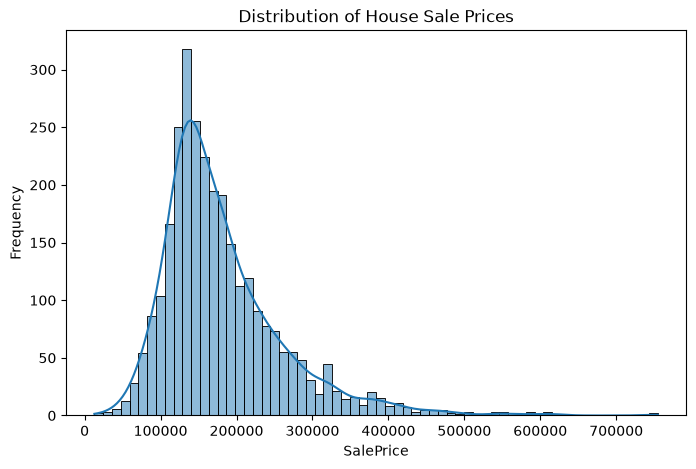

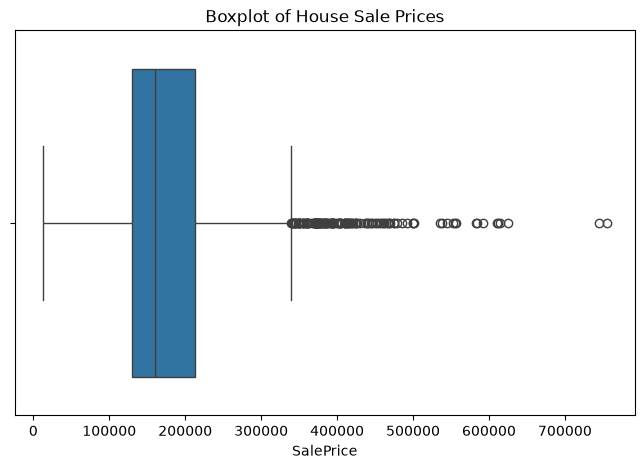

In [19]:

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("AmesHousing.csv")

# Inspect dataset
print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Descriptive statistics
print("\nDescriptive Statistics:")
print(df.describe())

# Target variable distribution
print("\nSalePrice Statistics:")
print(df["SalePrice"].describe())

print("\nSalePrice Skewness:")
print(df["SalePrice"].skew())

# Histogram of SalePrice
plt.figure(figsize=(8, 5))
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("SalePrice")
plt.ylabel("Frequency")
plt.show()

# Boxplot to identify outliers
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["SalePrice"])
plt.title("Boxplot of House Sale Prices")
plt.xlabel("SalePrice")
plt.show()

In [20]:
3. # Separate target variable and features
target = "SalePrice"

X = df.drop(columns=[target, "Order", "PID"], errors="ignore")
y = df[target]

# Handle missing values
# Numerical columns: fill with median
numerical_cols = X.select_dtypes(include=["number"]).columns
X[numerical_cols] = X[numerical_cols].fillna(
    X[numerical_cols].median()
)

# Categorical columns: fill with mode
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    mode_values = X[col].mode()
    if not mode_values.empty:
        X[col] = X[col].fillna(mode_values[0])
    else:
        X[col] = X[col].fillna("Unknown")

# One-Hot Encode categorical features
X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Check results
print("Original feature shape:", X.shape)
print("Encoded feature shape:", X_encoded.shape)

print("\nMissing values after handling:")
print(X_encoded.isnull().sum().sum())

print("\nEncoded dataset preview:")
print(X_encoded.head())

# Combine encoded features with target
processed_df = X_encoded.copy()
processed_df[target] = y

print("\nFinal dataset shape:", processed_df.shape)

# Save processed dataset
processed_df.to_csv("AmesHousing_processed.csv", index=False)

print("\nProcessed dataset saved successfully!")

C:\Users\Sandhya\AppData\Local\Temp\ipykernel_77008\1566797196.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


Original feature shape: (2930, 79)
Encoded feature shape: (2930, 260)

Missing values after handling:
0

Encoded dataset preview:
   MS SubClass  Lot Frontage  Lot Area  Overall Qual  Overall Cond  \
0           20         141.0     31770             6             5   
1           20          80.0     11622             5             6   
2           20          81.0     14267             6             6   
3           20          93.0     11160             7             5   
4           60          74.0     13830             5             5   

   Year Built  Year Remod/Add  Mas Vnr Area  BsmtFin SF 1  BsmtFin SF 2  ...  \
0        1960            1960         112.0         639.0           0.0  ...   
1        1961            1961           0.0         468.0         144.0  ...   
2        1958            1958         108.0         923.0           0.0  ...   
3        1968            1968           0.0        1065.0           0.0  ...   
4        1997            1998           0.0      

Top 15 Features Correlated with SalePrice:
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Mas Vnr Area      0.508285
TotRms AbvGrd     0.495474
Fireplaces        0.474558
BsmtFin SF 1      0.432914
Lot Frontage      0.357318
Name: SalePrice, dtype: float64


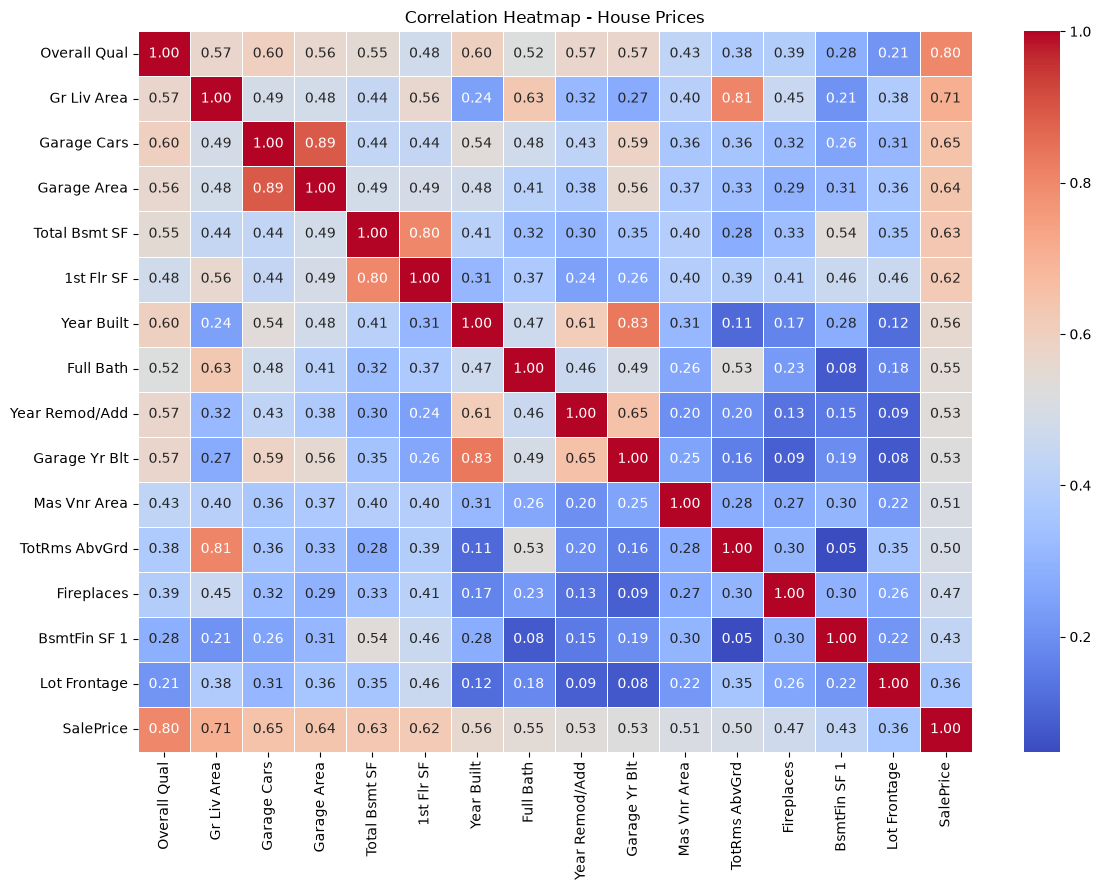

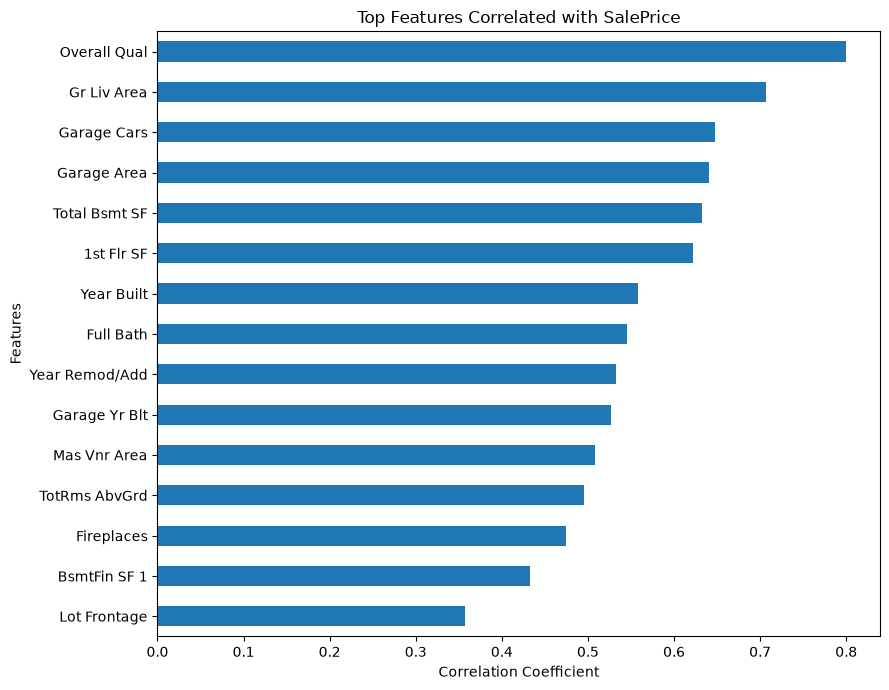

In [21]:
# Select numerical columns
numerical_df = df.select_dtypes(include=["number"])

# Calculate correlation with SalePrice
correlation = numerical_df.corr()["SalePrice"].drop("SalePrice")

# Display top 15 correlated features
top_features = correlation.abs().sort_values(
    ascending=False
).head(15).index

print("Top 15 Features Correlated with SalePrice:")
print(correlation.loc[top_features].sort_values(ascending=False))

# Create correlation heatmap
heatmap_features = list(top_features) + ["SalePrice"]
plt.figure(figsize=(12, 9))

sns.heatmap(
    df[heatmap_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - House Prices")
plt.tight_layout()
plt.show()

# Bar chart of correlations with SalePrice
correlation.loc[top_features].sort_values().plot(
    kind="barh",
    figsize=(9, 7),
    title="Top Features Correlated with SalePrice"
)

plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["SalePrice", "Order", "PID"], errors="ignore")
y = df["SalePrice"]

# Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining data percentage:", 
      round(len(X_train) / len(df) * 100, 2), "%")
print("Testing data percentage:", 
      round(len(X_test) / len(df) * 100, 2), "%")

Training features: (2344, 79)
Testing features: (586, 79)
Training target: (2344,)
Testing target: (586,)

Training data percentage: 80.0 %
Testing data percentage: 20.0 %


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
# Separate features and target
X = df.drop(columns=["SalePrice", "Order", "PID"], errors="ignore")
y = df["SalePrice"]

# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(include=["number"]).columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns

# Preprocess numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Create Linear Regression pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Split data into training and testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

print("Linear Regression model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("First 10 predicted prices:")
print(y_pred[:10])

C:\Users\Sandhya\AppData\Local\Temp\ipykernel_77008\880001836.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


Linear Regression model trained successfully!
Training samples: 2344
Testing samples: 586
First 10 predicted prices:
[142805.99637267 110016.65217519 188014.25662821 128450.72702829
 135771.92267427 186993.1665837  157913.83040684 140228.40885239
  96332.74725675 344156.51890856]


In [23]:

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Evaluate the model using test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Linear Regression Model Evaluation")
print("----------------------------------")
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))
print("R² Score (%):", round(r2 * 100, 2), "%")

Linear Regression Model Evaluation
----------------------------------
Mean Squared Error (MSE): 890186985.98
Root Mean Squared Error (RMSE): 29836.0
R² Score: 0.889
R² Score (%): 88.9 %


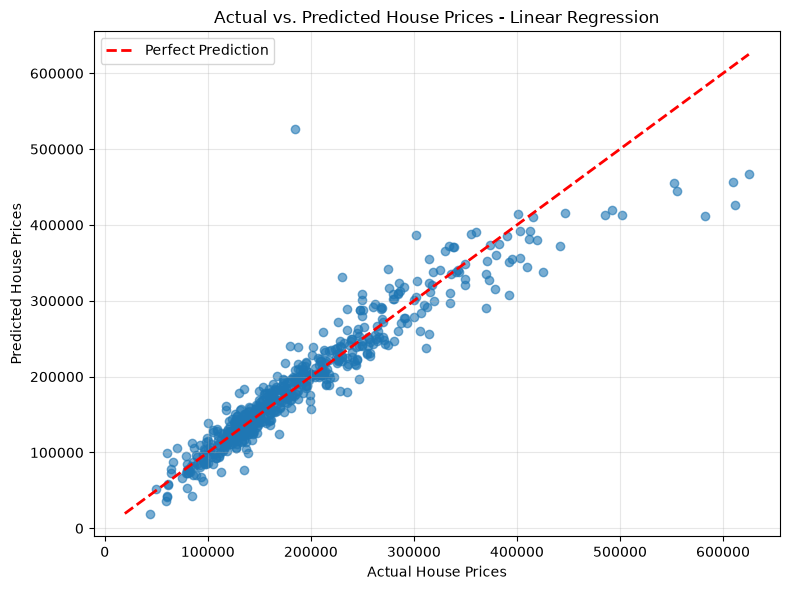

In [24]:
# Predict house prices
y_pred = model.predict(X_test)

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

# Add diagonal reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

# Add labels and title
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs. Predicted House Prices - Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

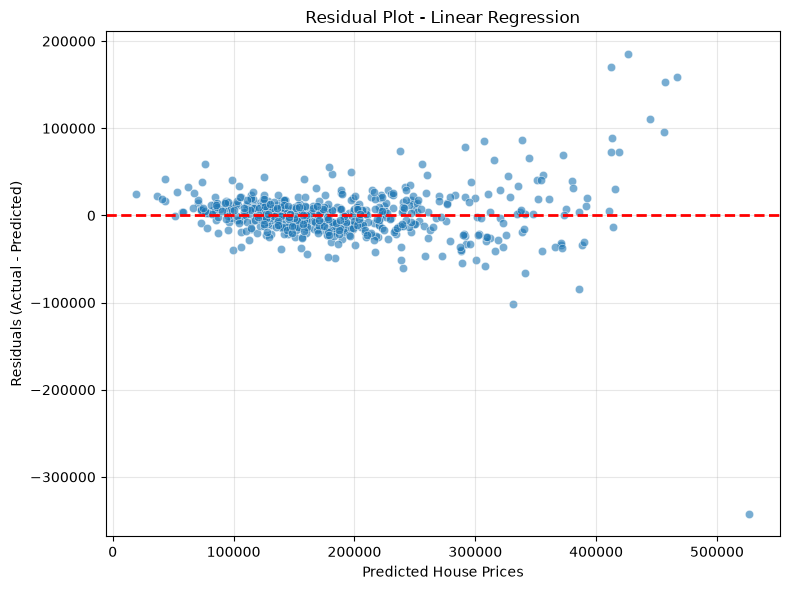

In [25]:
# Predict house prices
y_pred = model.predict(X_test)

# Calculate residuals
residuals = y_test - y_pred

# Create residual plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)

# Add zero reference line
plt.axhline(y=0, color="red", linestyle="--", linewidth=2)

# Add labels and title
plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot - Linear Regression")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Top 10 Features with Highest Positive Coefficients:
                  Feature  Coefficient
cat__Neighborhood_NoRidge 41513.695955
cat__Neighborhood_StoneBr 40707.356889
cat__Neighborhood_NridgHt 26649.640301
   cat__Roof Matl_WdShngl 24210.823714
   cat__Misc Feature_Gar2 20569.626254
          cat__Pool QC_Ex 20519.920112
cat__Exterior 1st_BrkFace 19721.380935
     cat__Kitchen Qual_Ex 19527.254514
    cat__Condition 1_PosN 16196.621468
     cat__Fireplace Qu_Ex 16048.725012

Top 10 Features with Highest Negative Coefficients:
                  Feature   Coefficient
   cat__Roof Matl_ClyTile -26984.552809
          cat__Pool QC_Gd -22572.707093
       cat__Lot Shape_IR3 -19170.635166
     cat__Bldg Type_Twnhs -17399.115575
   cat__Misc Feature_Elev -17288.340442
cat__Neighborhood_Mitchel -15697.695286
cat__Neighborhood_Gilbert -15377.537981
 cat__Neighborhood_NWAmes -15342.526467
cat__Neighborhood_Edwards -12842.827680
 cat__Exterior 1st_Stucco -12489.487062


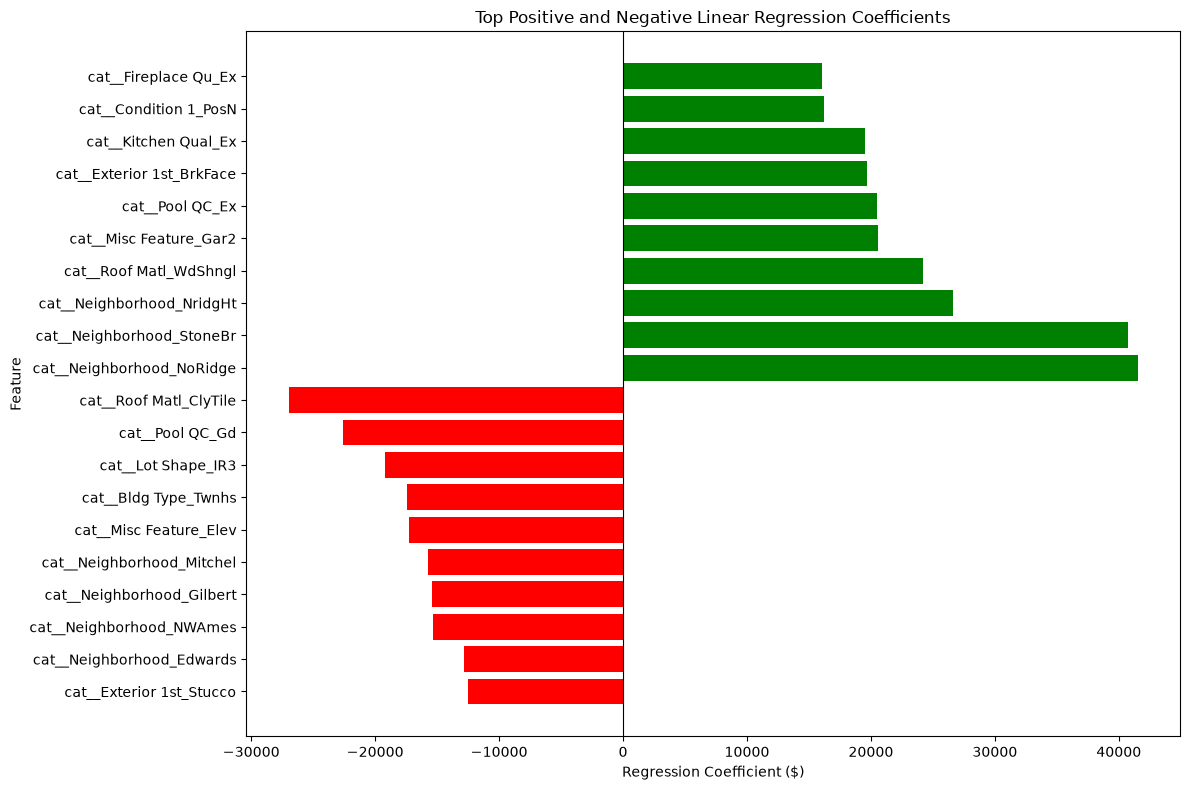

In [26]:
# Get feature names after preprocessing
preprocessor = model.named_steps["preprocessor"]
feature_names = preprocessor.get_feature_names_out()

# Get Linear Regression coefficients
coefficients = model.named_steps["regressor"].coef_

# Create coefficient DataFrame
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort coefficients
coef_df = coef_df.sort_values(
    by="Coefficient", ascending=False
)

# Display highest positive coefficients
print("Top 10 Features with Highest Positive Coefficients:")
print(coef_df.head(10).to_string(index=False))

# Display highest negative coefficients
print("\nTop 10 Features with Highest Negative Coefficients:")
print(coef_df.tail(10).sort_values(
    by="Coefficient"
).to_string(index=False))

# Plot top positive and negative coefficients
top_positive = coef_df.head(10)
top_negative = coef_df.tail(10)

plot_df = pd.concat([top_negative, top_positive])

plt.figure(figsize=(12, 8))
colors = [
    "green" if value > 0 else "red"
    for value in plot_df["Coefficient"]
]

plt.barh(
    plot_df["Feature"],
    plot_df["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Regression Coefficient ($)")
plt.ylabel("Feature")
plt.title("Top Positive and Negative Linear Regression Coefficients")
plt.tight_layout()
plt.show()

In [1]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Separate features and target
X = df.drop(columns=["SalePrice", "Order", "PID"], errors="ignore")
y = df["SalePrice"]

# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(include=["number"]).columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns

# Preprocessing pipelines
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Lasso Regression": Lasso(alpha=100.0, max_iter=20000)
}

results = []

# Train and evaluate each model
for name, regressor in models.items():
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)

    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    })

# Display comparison
results_df = pd.DataFrame(results)
print("Model Performance Comparison:")
print(results_df.round(3).to_string(index=False))

# Plot RMSE comparison
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Plot R2 comparison
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("R² Score Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("R² Score (Higher is Better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined